In [19]:
from pathlib import Path
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

edf_path = Path("../data/raw/chb01_03.edf")

assert edf_path.exists(), f"File not found: {edf_path}"

raw = mne.io.read_raw_edf(
    edf_path,
    preload=True,
    verbose=False
)

print("File loaded successfully!")
print(f"Sampling rate: {raw.info['sfreq']} Hz")
print(f"Number of channels: {len(raw.ch_names)}")
print(f"Duration: {raw.times[-1]:,.2f} seconds")
print(f"Duration: {raw.times[-1] / 60:.2f} minutes")
print(f"Channel names: {raw.ch_names}")
print(f"Channel types: {raw.get_channel_types()}")
print(f"Data shape: {raw.get_data().shape}")

C:\Users\SAMSUNG\AppData\Local\Temp\ipykernel_18300\2229413045.py:11: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(


File loaded successfully!
Sampling rate: 256.0 Hz
Number of channels: 23
Duration: 3,600.00 seconds
Duration: 60.00 minutes
Channel names: ['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1']
Channel types: ['eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg', 'eeg']
Data shape: (23, 921600)


In [44]:
eeg_data = raw.get_data()

print("Array dimensions:", eeg_data.shape)

# Inspect the first 10 samples of the first 3 channels
print(eeg_data[:3, :10])

# Basic statistics for each channel
channel_stats = pd.DataFrame({
    "channel": raw.ch_names,
    "mean": eeg_data.mean(axis=1),
    "std": eeg_data.std(axis=1),
    "min": eeg_data.min(axis=1),
    "max": eeg_data.max(axis=1),
})


channel_stats

Array dimensions: (23, 921600)
[[-1.77777778e-05  1.95360195e-07  1.95360195e-07  5.86080586e-07
   1.95360195e-07 -1.36752137e-06 -2.14896215e-06  5.86080586e-07
   2.93040293e-06 -5.86080586e-07]
 [ 3.92673993e-05  1.95360195e-07  1.95360195e-07  1.95360195e-07
   1.95360195e-07  1.75824176e-06  1.75824176e-06 -9.76800977e-07
  -2.14896215e-06  1.36752137e-06]
 [-3.71184371e-06  1.95360195e-07  1.95360195e-07  1.95360195e-07
   1.95360195e-07  1.95360195e-07  1.95360195e-07  1.95360195e-07
   1.95360195e-07  1.95360195e-07]]


,channel,mean,std,min,max
0,FP1-F7,1.792972e-07,0.000041,-0.000480,0.000500
1,F7-T7,1.699668e-07,0.000033,-0.000282,0.000306
2,T7-P7,2.115262e-07,0.000040,-0.000314,0.000310
3,P7-O1,2.129045e-07,0.000033,-0.000206,0.000199
4,FP1-F3,1.915001e-07,0.000047,-0.000513,0.000557
5,F3-C3,1.780686e-07,0.000047,-0.000431,0.000349
6,C3-P3,2.059151e-07,0.000034,-0.000317,0.000363
7,P3-O1,2.027239e-07,0.000042,-0.000386,0.000343
8,FP2-F4,1.950278e-07,0.000046,-0.000536,0.000451
9,F4-C4,1.785070e-07,0.000046,-0.000554,0.000395


In [48]:
eeg_microvolts = eeg_data * 1_000_000

print(eeg_microvolts[:3, :10])

[[-17.77777778   0.1953602    0.1953602    0.58608059   0.1953602
   -1.36752137  -2.14896215   0.58608059   2.93040293  -0.58608059]
 [ 39.26739927   0.1953602    0.1953602    0.1953602    0.1953602
    1.75824176   1.75824176  -0.97680098  -2.14896215   1.36752137]
 [ -3.71184371   0.1953602    0.1953602    0.1953602    0.1953602
    0.1953602    0.1953602    0.1953602    0.1953602    0.1953602 ]]


For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


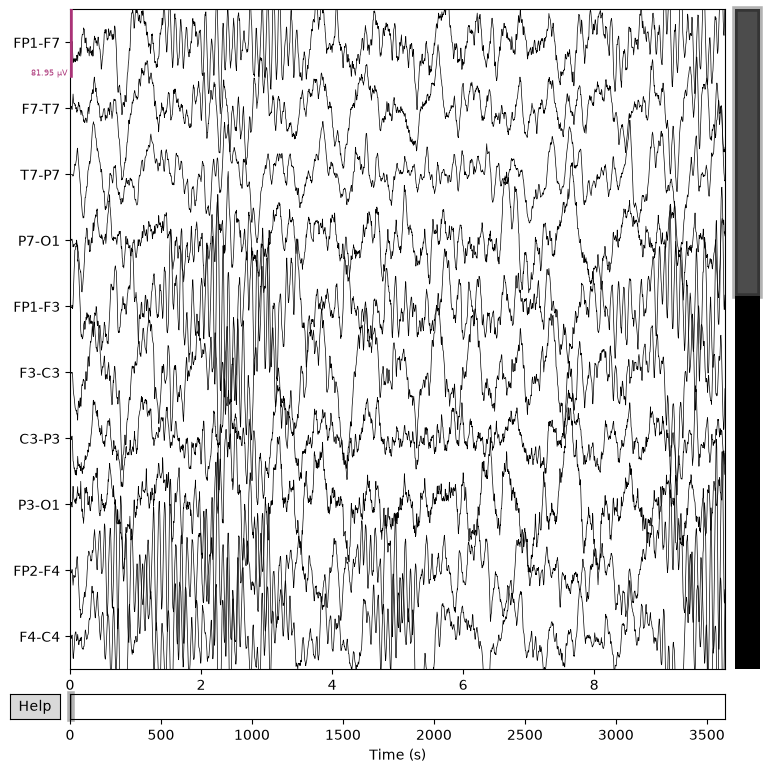

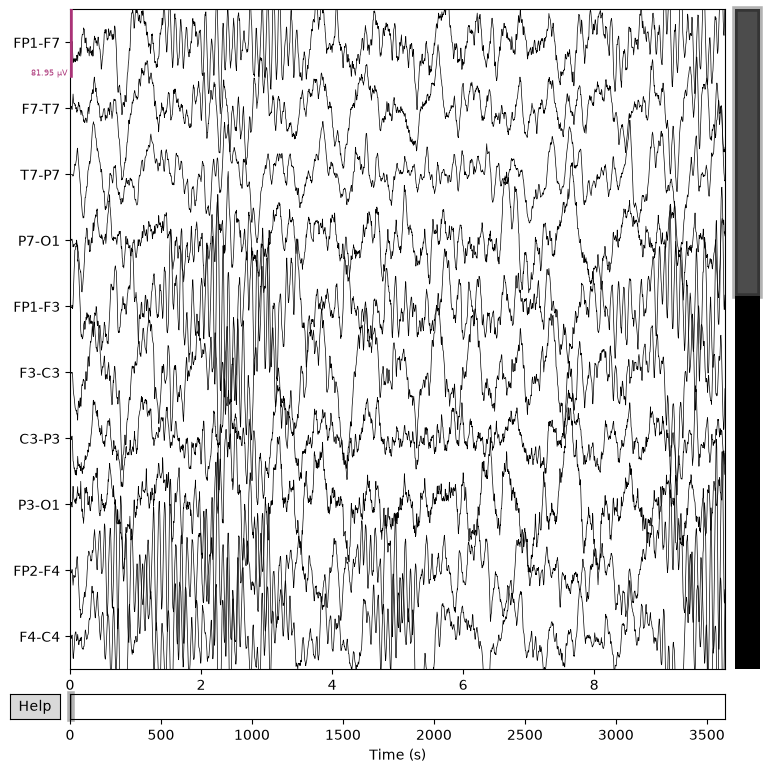

In [46]:
raw.plot(
    start=0,
    duration=10,
    n_channels=min(10, len(raw.ch_names)),
    scalings="auto",
    title="CHB01_03 - First 10 Seconds",
    show=True
)

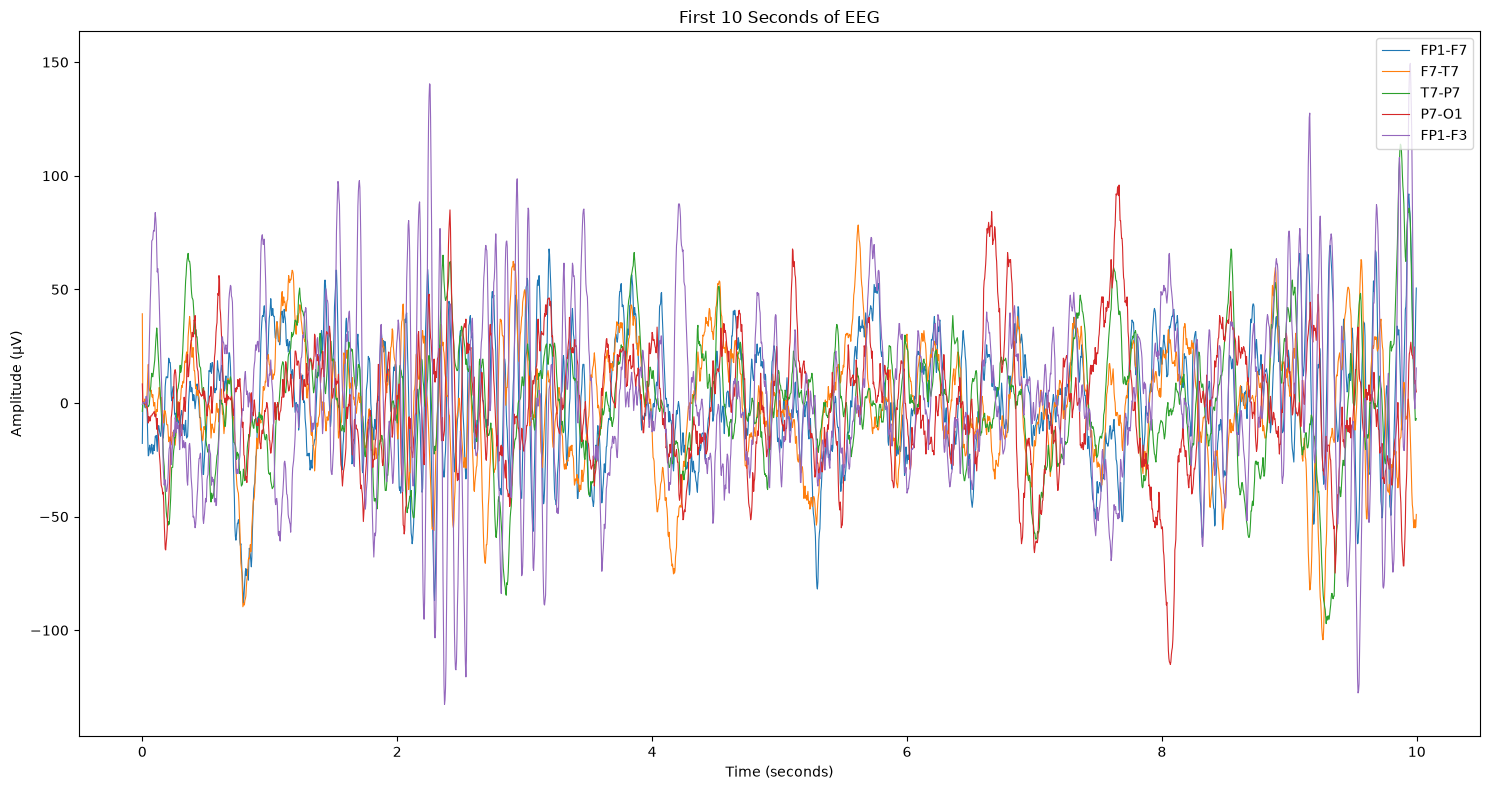

In [42]:
sampling_rate = raw.info["sfreq"]
duration_seconds = 10

number_of_samples = int(sampling_rate * duration_seconds)

time = np.arange(number_of_samples) / sampling_rate

plt.figure(figsize=(15, 8))

for channel_index in range(min(5, len(raw.ch_names))):
    plt.plot(
        time,
        eeg_microvolts[channel_index, :number_of_samples],
        label=raw.ch_names[channel_index],
        linewidth=0.8
    )

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (µV)")
plt.title("First 10 Seconds of EEG")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


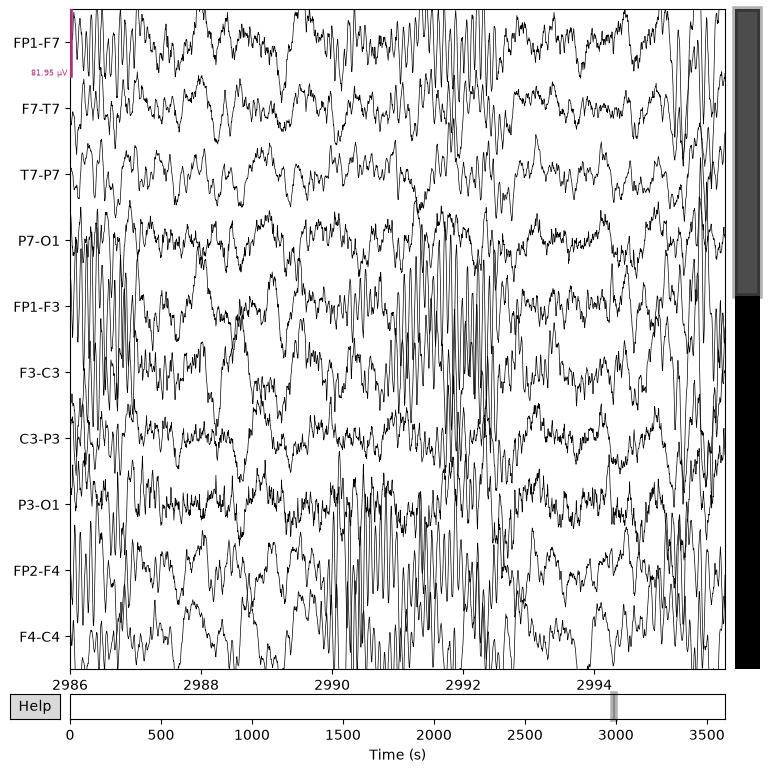

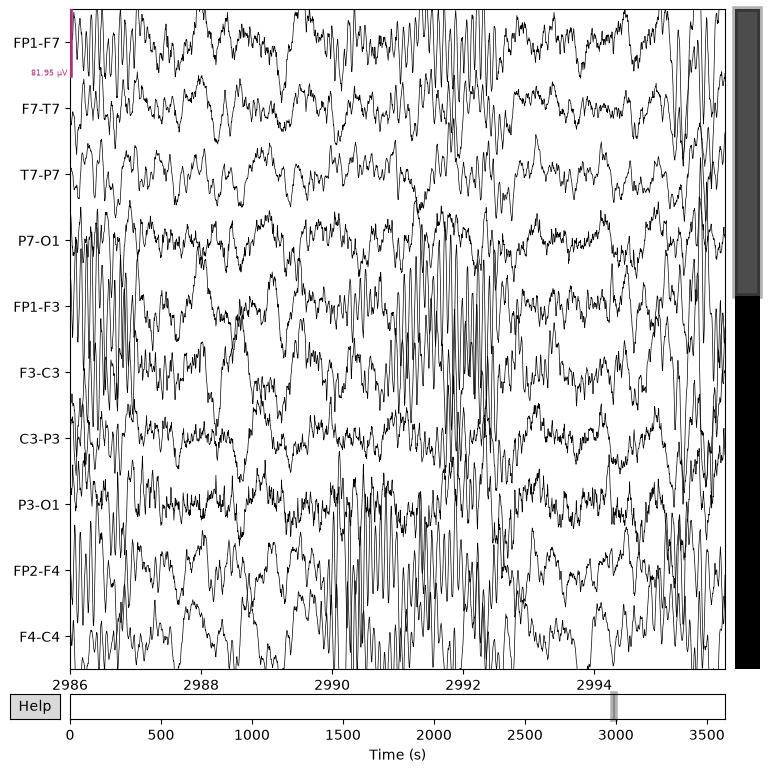

In [62]:
seizure_start = 2996
seizure_end = 3036

raw.plot(
    start=seizure_start - 10,
    duration=10,
    n_channels=min(10, len(raw.ch_names)),
    scalings="auto",
    title="EEG Before Annotated Seizure Onset",
    show=True
)

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


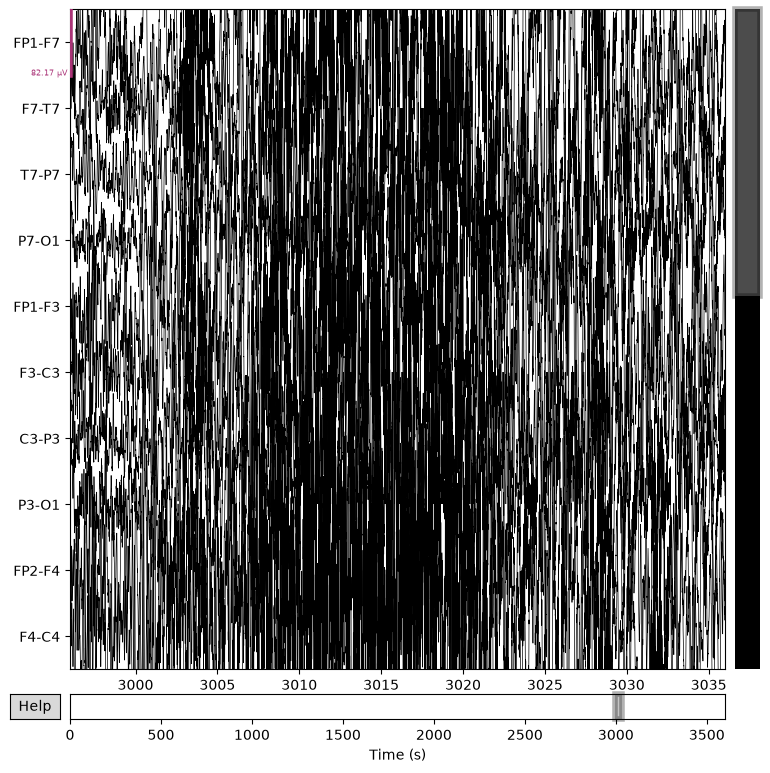

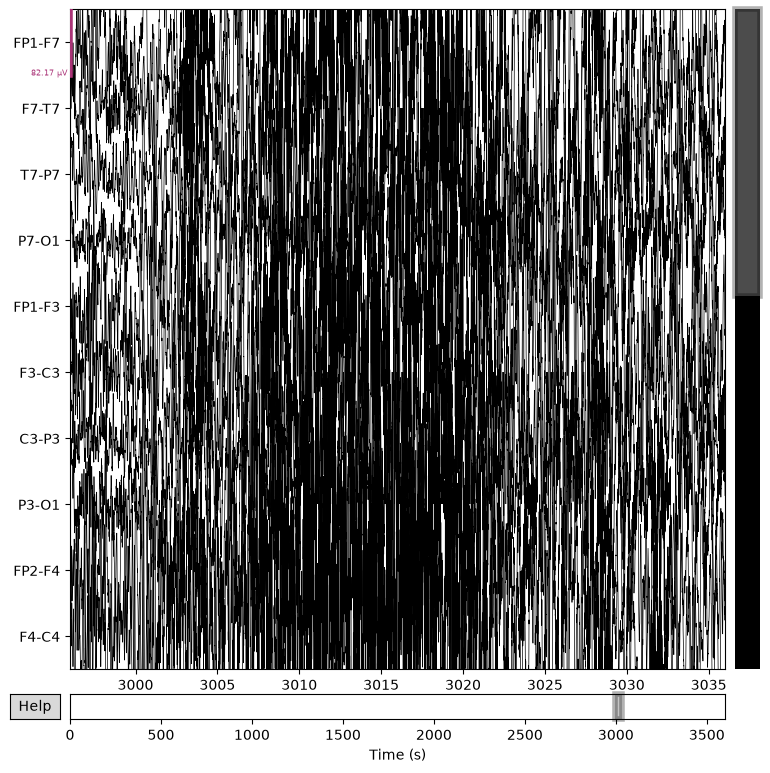

In [56]:
raw.plot(
    start=seizure_start,
    duration=seizure_end-seizure_start,
    n_channels=min(10, len(raw.ch_names)),
    scalings="auto",
    title="EEG During Annotated Seizure",
    show=True
)

In [60]:
annotations = pd.DataFrame([
    {
        "event": "seizure",
        "start_seconds": 2996,
        "end_seconds": 3036,
    }
])

annotations["duration_seconds"] = (
    annotations["end_seconds"] - annotations["start_seconds"]
)

display(annotations)

,event,start_seconds,end_seconds,duration_seconds
0,seizure,2996,3036,40


In [64]:
window_seconds = 5
samples_per_window = int(
    raw.info["sfreq"] * window_seconds
)

number_of_channels = len(raw.ch_names)

# Extract the first five seconds
first_window = eeg_data[:, :samples_per_window]

print("Window shape:", first_window.shape)
print("Channels:", number_of_channels)
print("Samples per channel:", samples_per_window)

Window shape: (23, 1280)
Channels: 23
Samples per channel: 1280


In [84]:
total_samples = eeg_data.shape[1]

number_of_windows = total_samples // samples_per_window

windows = eeg_data[
    :,
    :number_of_windows * samples_per_window
].reshape(
    number_of_channels,
    number_of_windows,
    samples_per_window
).transpose(1, 0, 2)

print("All windows shape:", windows.shape)

All windows shape: (720, 23, 1280)


In [89]:
channel_stats = pd.DataFrame({
    "channel": raw.ch_names,
    "mean_uV": eeg_microvolts.mean(axis=1),
    "std_uV": eeg_microvolts.std(axis=1),
    "min_uV": eeg_microvolts.min(axis=1),
    "max_uV": eeg_microvolts.max(axis=1),
})

print(
    channel_stats.round(2).to_string(index=False)
)

 channel  mean_uV  std_uV  min_uV  max_uV
  FP1-F7     0.18   40.71 -480.00  499.54
   F7-T7     0.17   32.89 -281.90  305.74
   T7-P7     0.21   39.95 -313.94  309.65
   P7-O1     0.21   33.22 -205.71  198.68
  FP1-F3     0.19   47.11 -513.21  556.58
   F3-C3     0.18   47.23 -431.16  349.50
   C3-P3     0.21   34.30 -316.68  363.17
   P3-O1     0.20   42.48 -386.23  343.25
  FP2-F4     0.20   45.95 -536.26  451.48
   F4-C4     0.18   46.20 -554.24  395.21
   C4-P4     0.20   36.02 -390.53  365.52
   P4-O2     0.19   49.76 -386.23  321.37
  FP2-F8     0.19   41.27 -469.06  445.23
   F8-T8     0.21   39.76 -547.20  481.95
 T8-P8-0     0.20   46.41 -721.07  476.48
   P8-O2     0.19   49.79 -378.41  479.61
   FZ-CZ     0.18   55.20 -540.17  595.26
   CZ-PZ     0.21   50.50 -491.72  469.45
   P7-T7     0.18   39.95 -309.26  314.33
  T7-FT9     0.19   24.62 -226.03  317.07
FT9-FT10     0.22   48.21 -512.43  485.47
 FT10-T8     0.22   25.46 -289.33  500.32
 T8-P8-1     0.20   46.41 -721.07 

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


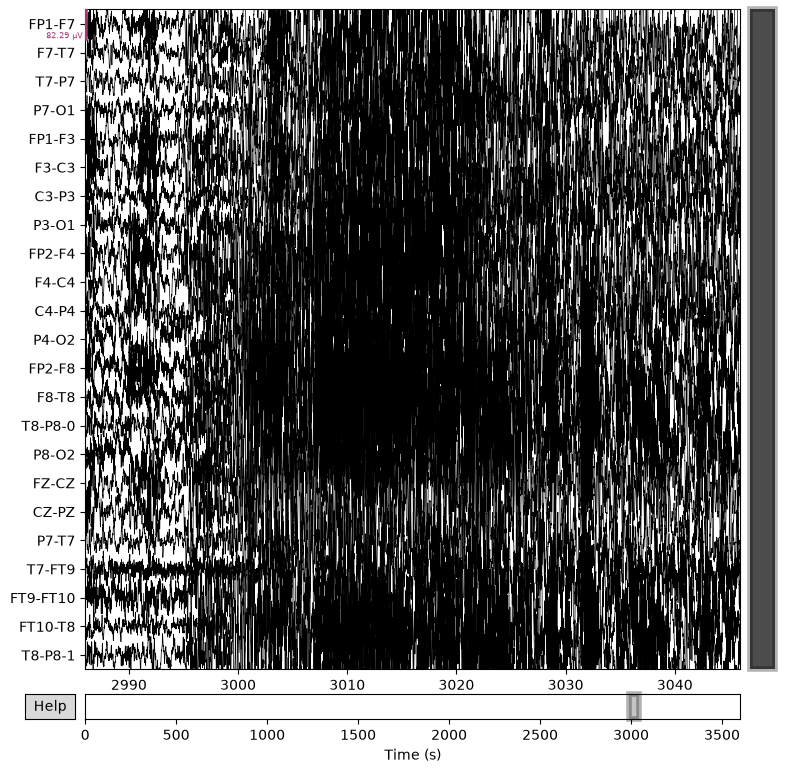

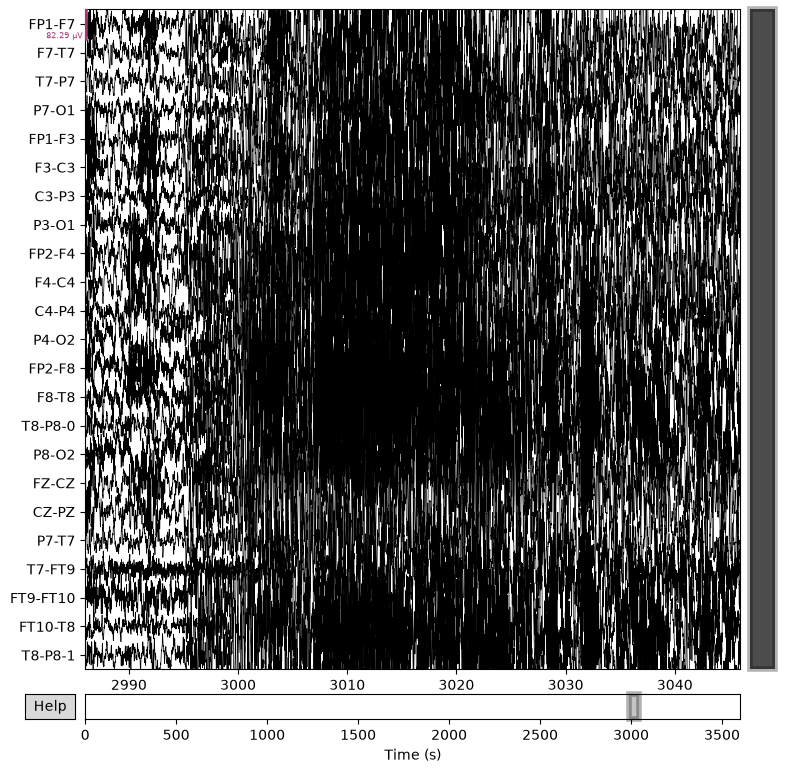

In [91]:
raw.plot(
    start=2986,
    duration=60,
    n_channels=23,
    scalings="auto",
    title="EEG Around the Annotated Seizure",
    show=True,
)

In [92]:
filtered_raw = raw.copy()

filtered_raw.filter(
    l_freq=0.5,
    h_freq=40.0,
    picks="eeg",
    method="fir",
    verbose=False,
)

print("Filtering completed.")

Filtering completed.


In [100]:
raw.info

<Info | 8 non-empty values
 bads: []
 ch_names: FP1-F7, F7-T7, T7-P7, P7-O1, FP1-F3, F3-C3, C3-P3, P3-O1, ...
 chs: 23 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 128.0 Hz
 meas_date: 2076-11-06 13:43:04 UTC
 nchan: 23
 projs: []
 sfreq: 256.0 Hz
 subject_info: <subject_info | his_id: Surrogate>
>

In [99]:
filtered_raw.info

<Info | 8 non-empty values
 bads: []
 ch_names: FP1-F7, F7-T7, T7-P7, P7-O1, FP1-F3, F3-C3, C3-P3, P3-O1, ...
 chs: 23 EEG
 custom_ref_applied: False
 highpass: 0.5 Hz
 lowpass: 40.0 Hz
 meas_date: 2076-11-06 13:43:04 UTC
 nchan: 23
 projs: []
 sfreq: 256.0 Hz
 subject_info: <subject_info | his_id: Surrogate>
>

### Let's check whether T8-P8-0 and T8-P8-1 are identical, and compare the original and filtered signal.

In [101]:
from scipy.stats import pearsonr

ch_a = eeg_microvolts[raw.ch_names.index("T8-P8-0")]
ch_b = eeg_microvolts[raw.ch_names.index("T8-P8-1")]

correlation = np.corrcoef(ch_a, ch_b)[0, 1]

print("Correlation:", correlation)
print("Maximum absolute difference (µV):",
      np.max(np.abs(ch_a - ch_b)))
print("Mean absolute difference (µV):",
      np.mean(np.abs(ch_a - ch_b)))

Correlation: 1.0
Maximum absolute difference (µV): 0.0
Mean absolute difference (µV): 0.0


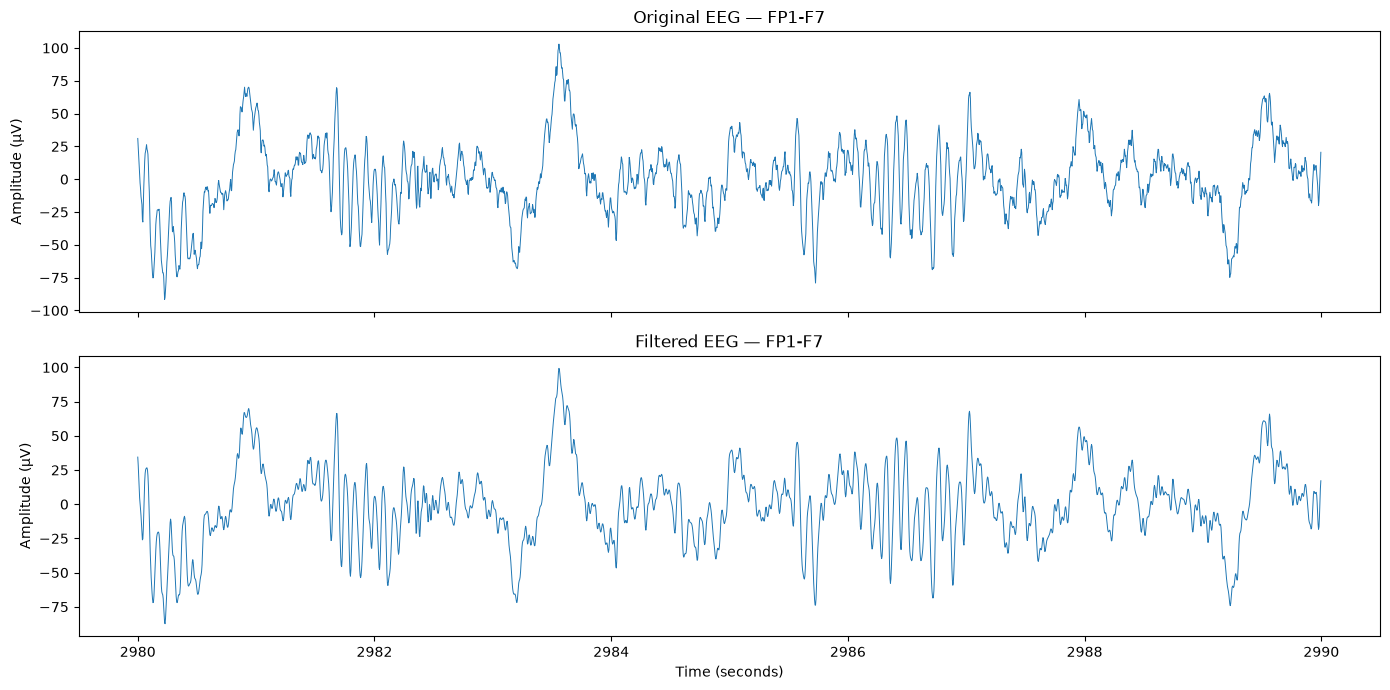

In [102]:
channel = "FP1-F7"
start = 2980
duration = 10

raw_segment = raw.get_data(
    picks=[channel],
    start=int(start * raw.info["sfreq"]),
    stop=int((start + duration) * raw.info["sfreq"])
)[0] * 1e6

filtered_segment = filtered_raw.get_data(
    picks=[channel],
    start=int(start * raw.info["sfreq"]),
    stop=int((start + duration) * raw.info["sfreq"])
)[0] * 1e6

time = np.arange(len(raw_segment)) / raw.info["sfreq"] + start

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(time, raw_segment, linewidth=0.7)
axes[0].set_title(f"Original EEG — {channel}")
axes[0].set_ylabel("Amplitude (µV)")

axes[1].plot(time, filtered_segment, linewidth=0.7)
axes[1].set_title(f"Filtered EEG — {channel}")
axes[1].set_ylabel("Amplitude (µV)")
axes[1].set_xlabel("Time (seconds)")

plt.tight_layout()
plt.show()

In [103]:
# Create a working copy of the filtered EEG
working_raw = filtered_raw.copy()

# Remove one of the two exactly identical channels
working_raw.drop_channels(["T8-P8-1"])

print("Remaining channels:", len(working_raw.ch_names))
print(working_raw.ch_names)

Remaining channels: 22
['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8']


In [104]:
import numpy as np
import pandas as pd

sfreq = working_raw.info["sfreq"]
window_seconds = 5
samples_per_window = int(sfreq * window_seconds)

# Shape: (channels, samples)
signal = working_raw.get_data()

# Use only complete, non-overlapping windows
n_windows = signal.shape[1] // samples_per_window
usable_samples = n_windows * samples_per_window

# Shape: (windows, channels, samples)
X_windows = signal[:, :usable_samples].reshape(
    len(working_raw.ch_names),
    n_windows,
    samples_per_window
).transpose(1, 0, 2)

window_starts = np.arange(n_windows) * window_seconds

window_table = pd.DataFrame({
    "window_id": np.arange(n_windows),
    "start_seconds": window_starts,
    "end_seconds": window_starts + window_seconds
})

print("Window array shape:", X_windows.shape)
print(window_table.head())
print(window_table.tail())

Window array shape: (720, 22, 1280)
   window_id  start_seconds  end_seconds
0          0              0            5
1          1              5           10
2          2             10           15
3          3             15           20
4          4             20           25
     window_id  start_seconds  end_seconds
715        715           3575         3580
716        716           3580         3585
717        717           3585         3590
718        718           3590         3595
719        719           3595         3600


In [112]:
seizure_start = 2996
seizure_end = 3036

window_table["overlaps_seizure"] = (
    (window_table["start_seconds"] < seizure_end) &
    (window_table["end_seconds"] > seizure_start)
)

print(window_table[window_table["overlaps_seizure"]])

     window_id  start_seconds  end_seconds  overlaps_seizure  preictal  \
599        599           2995         3000              True     False   
600        600           3000         3005              True     False   
601        601           3005         3010              True     False   
602        602           3010         3015              True     False   
603        603           3015         3020              True     False   
604        604           3020         3025              True     False   
605        605           3025         3030              True     False   
606        606           3030         3035              True     False   
607        607           3035         3040              True     False   

     interictal_candidate  label  
599                 False    NaN  
600                 False    NaN  
601                 False    NaN  
602                 False    NaN  
603                 False    NaN  
604                 False    NaN  
605           

In [113]:
display(window_table[window_table["overlaps_seizure"]])

,window_id,start_seconds,end_seconds,overlaps_seizure,preictal,interictal_candidate,label
599,599,2995,3000,True,False,False,NaN
600,600,3000,3005,True,False,False,NaN
601,601,3005,3010,True,False,False,NaN
602,602,3010,3015,True,False,False,NaN
603,603,3015,3020,True,False,False,NaN
604,604,3020,3025,True,False,False,NaN
605,605,3025,3030,True,False,False,NaN
606,606,3030,3035,True,False,False,NaN
607,607,3035,3040,True,False,False,NaN


In [114]:
import numpy as np

# Provisional experimental definitions
preictal_duration = 30 * 60  # 30 minutes

preictal_start = seizure_start - preictal_duration

# Check whether each 5-second window lies entirely within a period
window_table["preictal"] = (
    (window_table["start_seconds"] >= preictal_start) &
    (window_table["end_seconds"] <= seizure_start)
)

window_table["interictal_candidate"] = (
    (window_table["end_seconds"] <= preictal_start) |
    (window_table["start_seconds"] >= seizure_end)
)

# Exclude all windows that overlap the seizure itself
window_table["label"] = np.nan

window_table.loc[
    window_table["preictal"], "label"
] = 1

window_table.loc[
    window_table["interictal_candidate"], "label"
] = 0

print("Preictal starts at:", preictal_start, "seconds")
print(window_table["label"].value_counts(dropna=False))

Preictal starts at: 1196 seconds
label
1.0    359
0.0    351
NaN     10
Name: count, dtype: int64


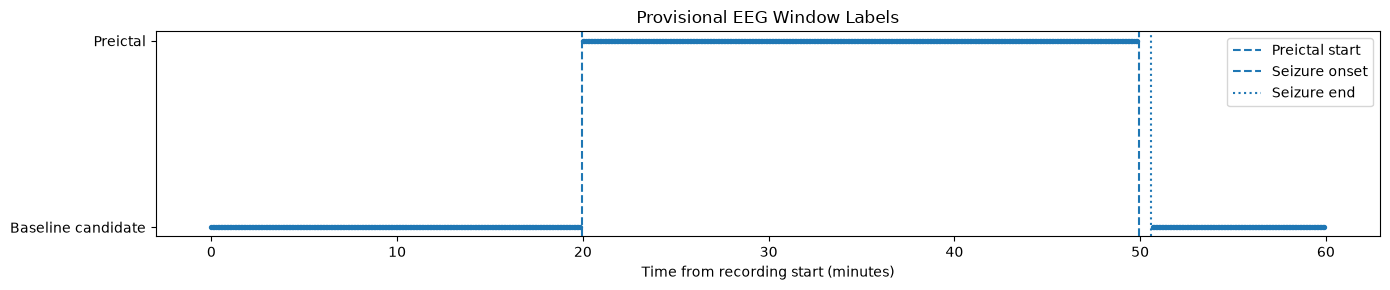

In [115]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 3))

plt.scatter(
    window_table["start_seconds"] / 60,
    window_table["label"],
    s=8
)

plt.axvline(preictal_start / 60, linestyle="--",
            label="Preictal start")
plt.axvline(seizure_start / 60, linestyle="--",
            label="Seizure onset")
plt.axvline(seizure_end / 60, linestyle=":",
            label="Seizure end")

plt.yticks([0, 1], ["Baseline candidate", "Preictal"])
plt.xlabel("Time from recording start (minutes)")
plt.title("Provisional EEG Window Labels")
plt.legend()
plt.tight_layout()
plt.show()

In [116]:
labeled_table = window_table.dropna(subset=["label"]).copy()

print("Total windows:", len(window_table))
print("Labeled windows:", len(labeled_table))
print("\nClass counts:")
print(labeled_table["label"].value_counts().sort_index())

print("\nClass proportions:")
print(
    labeled_table["label"]
    .value_counts(normalize=True)
    .sort_index()
    .round(3)
)

Total windows: 720
Labeled windows: 710

Class counts:
label
0.0    351
1.0    359
Name: count, dtype: int64

Class proportions:
label
0.0    0.494
1.0    0.506
Name: proportion, dtype: float64


## Next: converting EEG windows into STFT spectrograms

### Step 1 — Generate an STFT for one window

In [117]:
from scipy.signal import stft
import numpy as np
import matplotlib.pyplot as plt

# Select one five-second window and one EEG channel
window_index = 250
channel_index = 0

signal_window = X_windows[window_index, channel_index, :]

# STFT configuration
frequencies, times, Zxx = stft(
    signal_window,
    fs=sfreq,
    nperseg=128,
    noverlap=96
)

# Magnitude of the time-frequency representation
spectrogram = np.abs(Zxx)

print("Original window shape:", signal_window.shape)
print("Spectrogram shape:", spectrogram.shape)
print("Frequency bins:", len(frequencies))
print("Time frames:", len(times))

Original window shape: (1280,)
Spectrogram shape: (65, 41)
Frequency bins: 65
Time frames: 41


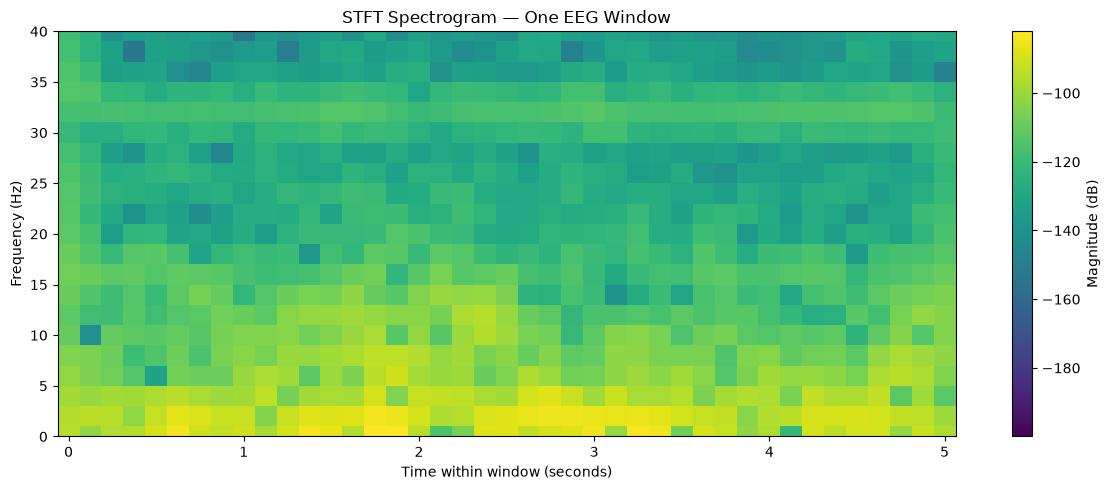

In [118]:
plt.figure(figsize=(12, 5))

plt.pcolormesh(
    times,
    frequencies,
    20 * np.log10(spectrogram + 1e-10),
    shading="auto"
)

plt.ylim(0, 40)
plt.xlabel("Time within window (seconds)")
plt.ylabel("Frequency (Hz)")
plt.title("STFT Spectrogram — One EEG Window")
plt.colorbar(label="Magnitude (dB)")
plt.tight_layout()
plt.show()

### 3. Extract STFT features for all labeled windows

In [119]:
from scipy.signal import stft

# Keep only windows assigned a provisional label
labeled_table = window_table.dropna(subset=["label"]).copy()

selected_indices = labeled_table["window_id"].to_numpy()
y = labeled_table["label"].astype("int64").to_numpy()

# X_windows has shape: (windows, channels, samples)
X_selected = X_windows[selected_indices]

nperseg = 128
noverlap = 96

# Determine output dimensions using the first channel
f, t, z = stft(
    X_selected[0, 0],
    fs=sfreq,
    nperseg=nperseg,
    noverlap=noverlap
)

# Retain frequencies up to 40 Hz
frequency_mask = (f >= 0) & (f <= 40)

# Allocate: examples, channels, frequencies, time frames
X_stft = np.empty(
    (
        len(X_selected),
        X_selected.shape[1],
        frequency_mask.sum(),
        len(t)
    ),
    dtype=np.float32
)

for i in range(len(X_selected)):
    for ch in range(X_selected.shape[1]):
        _, _, z = stft(
            X_selected[i, ch],
            fs=sfreq,
            nperseg=nperseg,
            noverlap=noverlap
        )

        X_stft[i, ch] = np.abs(z)[frequency_mask].astype(np.float32)

print("STFT dataset shape:", X_stft.shape)
print("Labels shape:", y.shape)
print("Class counts:", np.unique(y, return_counts=True))

STFT dataset shape: (710, 22, 21, 41)
Labels shape: (710,)
Class counts: (array([0, 1]), array([351, 359]))


### Selecting one baseline window and one preictal window

In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import stft

# Select windows using their existing labels
baseline_candidates = window_table[
    (window_table["label"] == 0) &
    (window_table["end_seconds"] <= preictal_start)
]

preictal_candidates = window_table[
    window_table["label"] == 1
]

# Select a baseline window around 10 minutes
baseline_window_id = int(
    baseline_candidates.iloc[
        np.argmin(
            np.abs(baseline_candidates["start_seconds"].to_numpy() - 600)
        )
    ]["window_id"]
)

# Select a preictal window around 10 minutes before seizure onset
preictal_window_id = int(
    preictal_candidates.iloc[
        np.argmin(
            np.abs(
                preictal_candidates["start_seconds"].to_numpy()
                - (seizure_start - 600)
            )
        )
    ]["window_id"]
)

print("Baseline window:", baseline_window_id)
print("Preictal window:", preictal_window_id)
print("Baseline start:", window_table.loc[
    baseline_window_id, "start_seconds"
], "seconds")
print("Preictal start:", window_table.loc[
    preictal_window_id, "start_seconds"
], "seconds")

Baseline window: 120
Preictal window: 479
Baseline start: 600 seconds
Preictal start: 2395 seconds


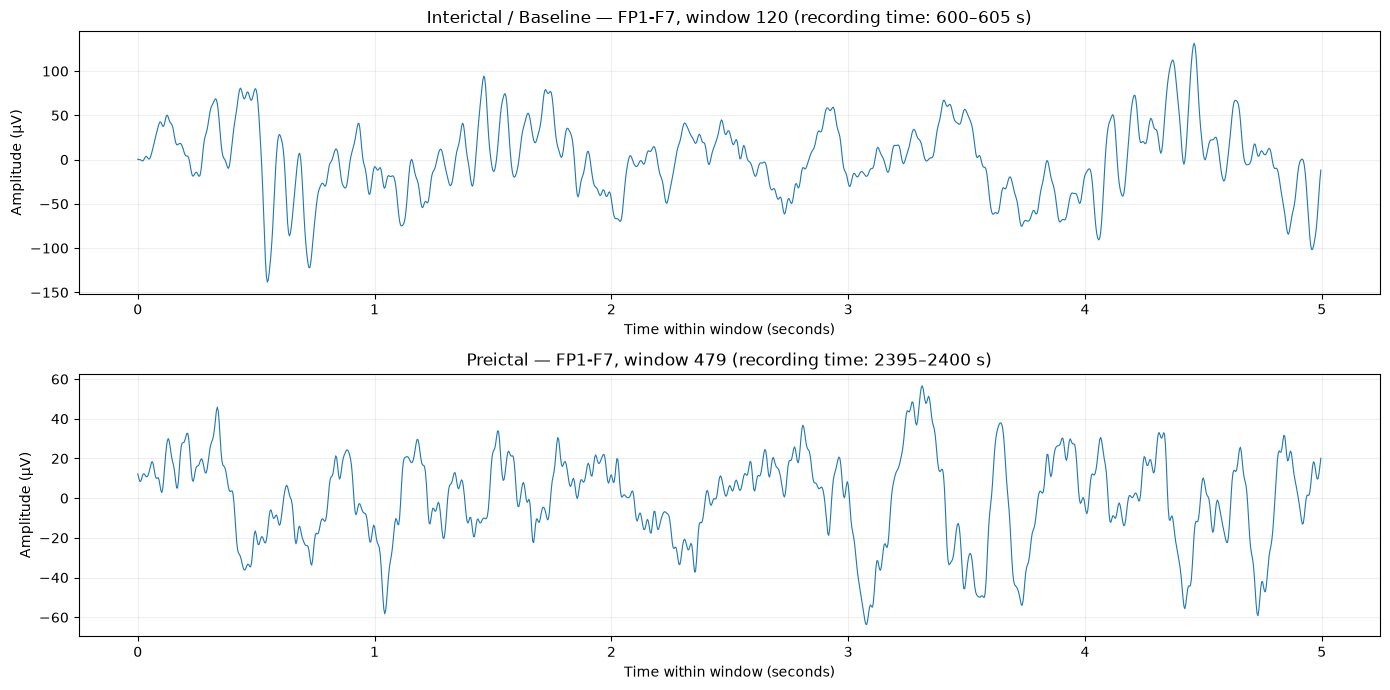

In [121]:
channel_name = "FP1-F7"
channel_idx = working_raw.ch_names.index(channel_name)

window_ids = [baseline_window_id, preictal_window_id]
titles = ["Interictal / Baseline", "Preictal"]

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

for ax, window_id, title in zip(axes, window_ids, titles):
    eeg = X_windows[window_id, channel_idx, :] * 1e6
    time = np.arange(len(eeg)) / sfreq

    ax.plot(time, eeg, linewidth=0.8)
    ax.set_title(
        f"{title} — {channel_name}, "
        f"window {window_id} "
        f"(recording time: {window_id * 5}–{window_id * 5 + 5} s)"
    )
    ax.set_xlabel("Time within window (seconds)")
    ax.set_ylabel("Amplitude (µV)")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

C:\Users\SAMSUNG\AppData\Local\Temp\ipykernel_18300\661607779.py:29: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


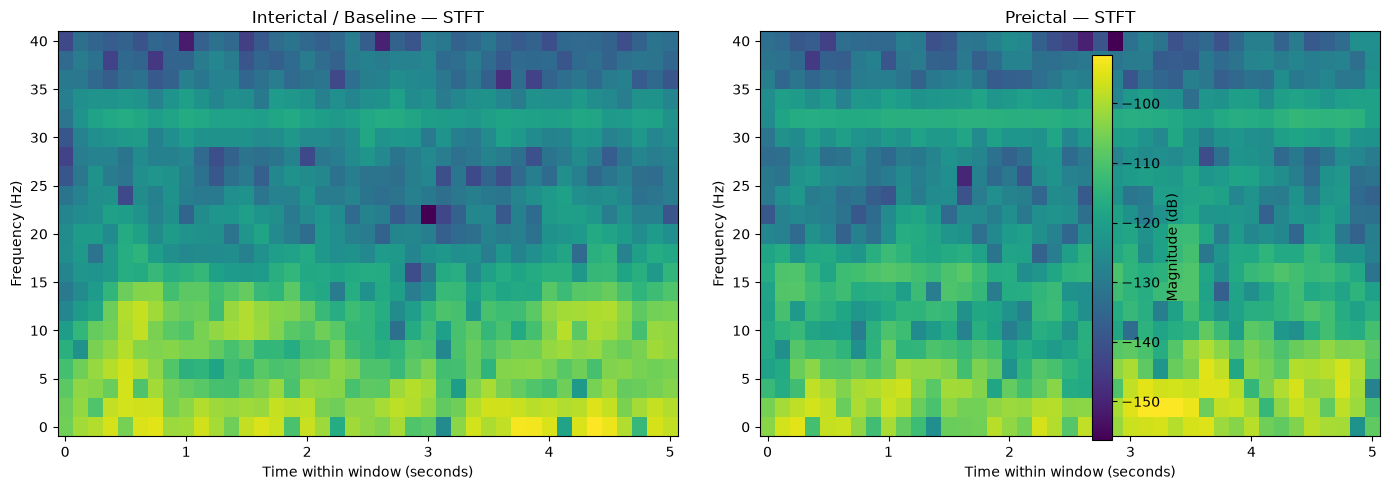

In [122]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, window_id, title in zip(axes, window_ids, titles):
    eeg = X_windows[window_id, channel_idx, :]

    f, t, Z = stft(
        eeg,
        fs=sfreq,
        nperseg=128,
        noverlap=96
    )

    magnitude_db = 20 * np.log10(np.abs(Z) + 1e-10)
    mask = (f >= 0) & (f <= 40)

    mesh = ax.pcolormesh(
        t,
        f[mask],
        magnitude_db[mask],
        shading="auto",
        cmap="viridis"
    )

    ax.set_title(f"{title} — STFT")
    ax.set_xlabel("Time within window (seconds)")
    ax.set_ylabel("Frequency (Hz)")

fig.colorbar(mesh, ax=axes, label="Magnitude (dB)")
plt.tight_layout()
plt.show()

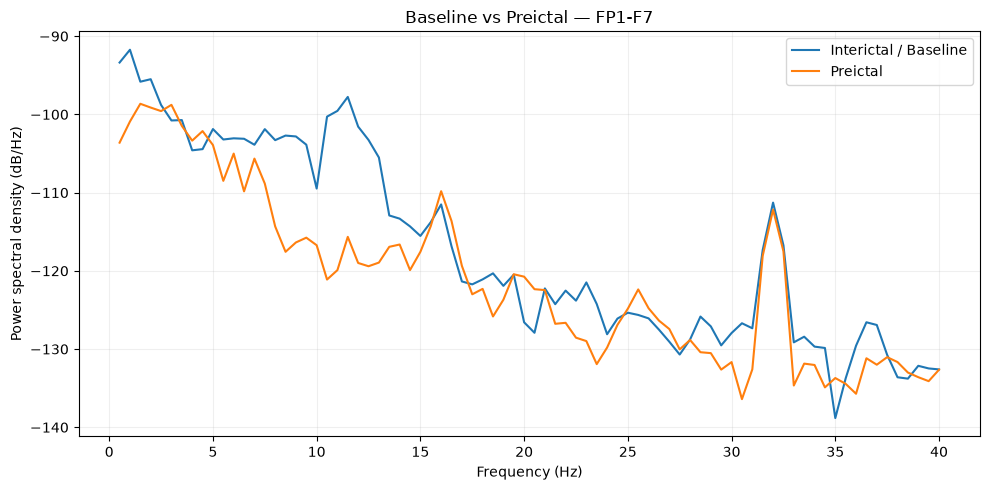

In [123]:
from scipy.signal import welch

fig, ax = plt.subplots(figsize=(10, 5))

for window_id, title in zip(window_ids, titles):
    eeg = X_windows[window_id, channel_idx, :]

    f, psd = welch(
        eeg,
        fs=sfreq,
        nperseg=512
    )

    mask = (f >= 0.5) & (f <= 40)

    ax.plot(
        f[mask],
        10 * np.log10(psd[mask] + 1e-20),
        label=title
    )

ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power spectral density (dB/Hz)")
ax.set_title(f"Baseline vs Preictal — {channel_name}")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()